In [52]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import os
import joblib
from sklearn.preprocessing import RobustScaler
from sklearn.metrics import classification_report, average_precision_score, confusion_matrix, precision_recall_curve
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
from sklearn.manifold import TSNE
from sklearn.cluster import AgglomerativeClustering, HDBSCAN
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import dendrogram, linkage
from scipy.spatial.distance import pdist
from sklearn.mixture import BayesianGaussianMixture
import torch
import time
import torch.nn as nn
from pytorch_tabnet.pretraining import TabNetPretrainer
from pytorch_tabnet.tab_model import TabNetClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler, QuantileTransformer
import pickle
import joblib
from sklearn.covariance import OAS
from sklearn.svm import SVC
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics.pairwise import laplacian_kernel


In [2]:
data = pd.read_csv(r'C:\Users\Anton\Downloads\archive (1)\creditcard.csv')
data = data.drop(['Time'], axis=1)

y = data['Class']
X = data.drop(['Class'], axis=1)

# scaling the amount to the other features
X['Amount'] = np.log(X['Amount'] + 0.001)
scaler = RobustScaler()
X['Amount'] = scaler.fit_transform(X[['Amount']])

X

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,...,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount
0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,0.090794,...,0.251412,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,0.730845
1,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,-0.166974,...,-0.069083,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,-0.801054
2,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,0.207643,...,0.524980,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,1.084841
3,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,-0.054952,...,-0.208038,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,0.657702
4,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,0.753074,...,0.408542,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,0.441202
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
284802,-11.881118,10.071785,-9.834783,-2.066656,-5.364473,-2.606837,-4.918215,7.305334,1.914428,4.356170,...,1.475829,0.213454,0.111864,1.014480,-0.509348,1.436807,0.250034,0.943651,0.823731,-1.277597
284803,-0.732789,-0.055080,2.035030,-0.738589,0.868229,1.058415,0.024330,0.294869,0.584800,-0.975926,...,0.059616,0.214205,0.924384,0.012463,-1.016226,-0.606624,-0.395255,0.068472,-0.053527,0.045517
284804,1.919565,-0.301254,-3.249640,-0.557828,2.630515,3.031260,-0.296827,0.708417,0.432454,-0.484782,...,0.001396,0.232045,0.578229,-0.037501,0.640134,0.265745,-0.087371,0.004455,-0.026561,0.429532
284805,-0.240440,0.530483,0.702510,0.689799,-0.377961,0.623708,-0.686180,0.679145,0.392087,-0.399126,...,0.127434,0.265245,0.800049,-0.163298,0.123205,-0.569159,0.546668,0.108821,0.104533,-0.300571


In [3]:
model_path = 'bgm_model_antoni.joblib'

if os.path.exists(model_path):
    print("Loading saved model...")
    bgm = joblib.load(model_path)
else:
    bgm = BayesianGaussianMixture(
        n_components=15,
        weight_concentration_prior_type='dirichlet_process',
        weight_concentration_prior=1e-3,
        max_iter=500,
        random_state=42,
        verbose=1
    )
    bgm.fit(X)
    joblib.dump(bgm, model_path)
    print(f"Model saved locally to {model_path}")

Loading saved model...


In [4]:
weights = np.round(bgm.weights_, 4)
active_clusters = np.where(weights > 0.005)[0]

print(f"active clusters: {weights[active_clusters]}")


active clusters: [0.1173 0.0324 0.0513 0.0137 0.3501 0.0557 0.1214 0.007  0.0071 0.0532
 0.0163 0.0096 0.0803 0.045  0.0396]


In [5]:
results = pd.DataFrame()
results['Cluster'] = bgm.predict(X)
results['True_Class'] = y.values 

crosstab = pd.crosstab(results['Cluster'], results['True_Class'])

crosstab = crosstab.rename(columns={0: 'Normal', 1: 'Fraud'})

if 'Fraud' not in crosstab.columns: crosstab['Fraud'] = 0
if 'Normal' not in crosstab.columns: crosstab['Normal'] = 0

crosstab['Fraud_Rate (%)'] = (crosstab['Fraud'] / (crosstab['Normal'] + crosstab['Fraud'])) * 100

print(crosstab.sort_values(by='Fraud_Rate (%)', ascending=False))

True_Class  Normal  Fraud  Fraud_Rate (%)
Cluster                                  
8             1675    346       17.120238
7             1942     61        3.045432
3             3856      7        0.181206
11            2718      4        0.146951
2            14592     10        0.068484
10            4619      3        0.064907
4            99669     39        0.039114
0            33313     11        0.033009
9            15165      5        0.032960
12           22927      4        0.017444
13           12828      1        0.007795
5            15851      1        0.006308
1             9232      0        0.000000
6            34648      0        0.000000
14           11280      0        0.000000


In [6]:
#  We separate 2 good clusters from the rest of the data
best_two_clusters = results[results['Cluster'].isin([7, 8])]
X_best_two_clusters = X.iloc[best_two_clusters.index]
y_best_two_clusters = y.iloc[best_two_clusters.index]

X_worst = X[~X.index.isin(best_two_clusters.index)]
y_worst = y[~y.index.isin(best_two_clusters.index)]

## Fraud clustering

In [20]:
data_worst = pd.concat([X_worst, y_worst], axis=1)

worst1 = data_worst[data_worst['Class'] == 1]
worst0 = data_worst[data_worst['Class'] == 0]

X_worst1 = worst1.drop(['Class'], axis=1)
y_worst1 = worst1['Class']

X_worst0 = worst0.drop(['Class'], axis=1)
y_worst0 = worst0['Class']

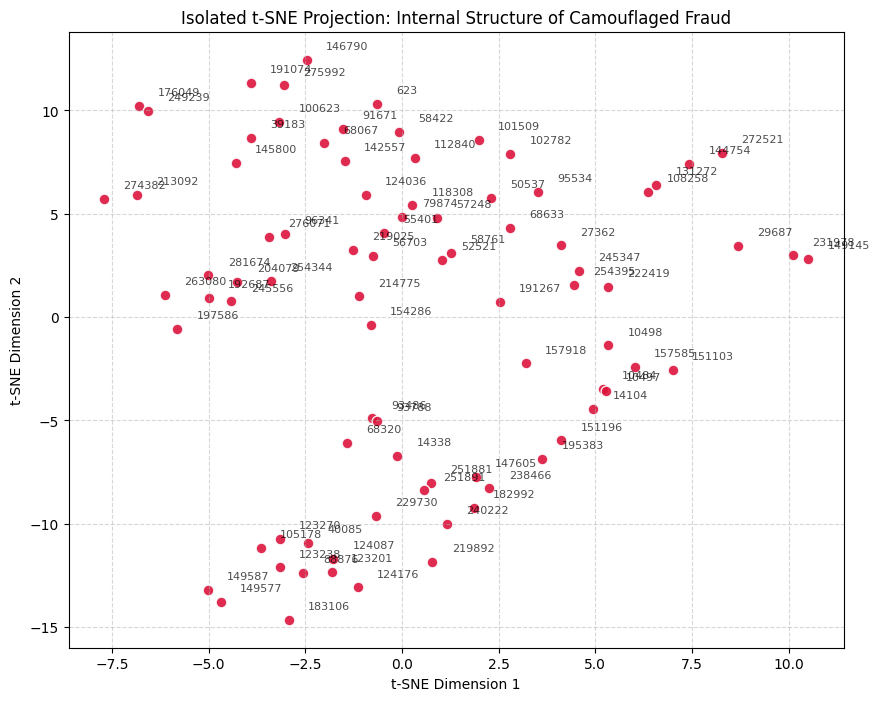

In [21]:
tsne = TSNE(n_components=2, perplexity= 15, random_state=42)
tsne_fraud = tsne.fit_transform(X_worst1)

plt.figure(figsize=(10, 8))

plt.scatter(
    tsne_fraud[:, 0], 
    tsne_fraud[:, 1], 
    c='crimson', 
    alpha=0.9, 
    s=60, 
    edgecolor='white'
)

plt.title("Isolated t-SNE Projection: Internal Structure of Camouflaged Fraud")
plt.xlabel("t-SNE Dimension 1")
plt.ylabel("t-SNE Dimension 2")
plt.grid(True, linestyle='--', alpha=0.5)

for i, txt in enumerate(X_worst1.index):
    plt.annotate(txt, (tsne_fraud[i, 0] + 0.5, tsne_fraud[i, 1] + 0.5), fontsize=8, alpha=0.7)

plt.show()

We observe that there are no clearly identifiable groupings, although data does exhibit patterns. 

In [54]:
agg_cosine = AgglomerativeClustering(
    n_clusters=None,
    distance_threshold=0.65,
    metric='cosine',
    linkage='average'
)
labels_agg = agg_cosine.fit_predict(X_worst1)

bgmm_diag = BayesianGaussianMixture(
    n_components=10,
    covariance_type='diag',
    weight_concentration_prior=10.0,
    max_iter=500,
    random_state=42
)
labels_gmm = bgmm_diag.fit_predict(X_worst1)

hdb = HDBSCAN(
    min_cluster_size=3,
    min_samples=2,
    metric='euclidean'
)
labels_hdb = hdb.fit_predict(X_worst1)

for name, lbls in [("d-gmm", labels_gmm), 
                   ("cosine agglomerative", labels_agg), 
                   ("HDBSCAN", labels_hdb)]:
    unique, counts = np.unique(lbls, return_counts=True)
    cluster_summary = dict(zip(unique.tolist(), counts.tolist()))
    print(f"{name:<25} | Found {len(unique):>2} groups | Sizes: {cluster_summary}")


d-gmm                     | Found 10 groups | Sizes: {0: 4, 1: 12, 2: 9, 3: 1, 4: 21, 5: 1, 6: 2, 7: 18, 8: 16, 9: 1}
cosine agglomerative      | Found 14 groups | Sizes: {0: 10, 1: 7, 2: 44, 3: 3, 4: 2, 5: 1, 6: 7, 7: 1, 8: 1, 9: 2, 10: 4, 11: 1, 12: 1, 13: 1}
HDBSCAN                   | Found  8 groups | Sizes: {-1: 45, 0: 4, 1: 3, 2: 6, 3: 3, 4: 4, 5: 11, 6: 9}


c:\Users\Anton\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\cluster\_hdbscan\hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(


In [55]:
df_clusters = pd.DataFrame({
    'gmm': labels_gmm,
    'cos': labels_agg,
    'HDBSCAN': labels_hdb
}, index=X_worst1.index)

methods = ['HDBSCAN', 'cos', 'gmm']

for method in methods:
    print(f"\n{method}")
    grouped = df_clusters.groupby(method)
    for cluster_id, indices in grouped.groups.items():
        label = "noise" if cluster_id == -1 and 'HDBSCAN' in method else f"Cluster {cluster_id}"
        print(f"{label} ({len(indices)} frauds): {list(indices)}")

overlap_matrix1 = pd.crosstab(
    df_clusters['cos'], 
    df_clusters['HDBSCAN'], 
    rownames=['cosine (rows)'], 
    colnames=['HDBSCAN (cols)']
)
print(overlap_matrix1)

overlap_matrix2 = pd.crosstab(
    df_clusters['cos'], 
    df_clusters['gmm'], 
    rownames=['cos (rows)'], 
    colnames=['gmm (cols)']
)
print(overlap_matrix2)

overlap_matrix3 = pd.crosstab(
    df_clusters['HDBSCAN'], 
    df_clusters['gmm'], 
    rownames=['HDBSCAN (rows)'], 
    colnames=['gmm (cols)']
)
print(overlap_matrix3)


HDBSCAN
noise (45 frauds): [623, 10498, 29687, 39183, 50537, 58422, 68320, 68633, 91671, 95534, 96341, 100623, 101509, 102782, 108258, 112840, 124176, 131272, 144754, 145800, 146790, 149145, 149577, 149587, 151103, 151196, 154286, 157918, 176049, 183106, 191074, 191267, 195383, 197586, 213092, 214775, 219892, 222419, 229730, 231978, 249239, 272521, 274382, 275992, 276071]
Cluster 0 (4 frauds): [10484, 10497, 14104, 157585]
Cluster 1 (3 frauds): [27362, 245347, 254395]
Cluster 2 (6 frauds): [192687, 204079, 245556, 254344, 263080, 281674]
Cluster 3 (3 frauds): [40085, 105178, 123270]
Cluster 4 (4 frauds): [88876, 123201, 123238, 124087]
Cluster 5 (11 frauds): [52521, 55401, 56703, 57248, 58761, 68067, 79874, 118308, 124036, 142557, 219025]
Cluster 6 (9 frauds): [14338, 93486, 93788, 147605, 182992, 238466, 240222, 251881, 251891]

cos
Cluster 0 (10 frauds): [39183, 68067, 91671, 100623, 142557, 146790, 176049, 191074, 249239, 275992]
Cluster 1 (7 frauds): [623, 58422, 145800, 157918, 1

In [56]:
def assign_refined_expert(row):
    gmm = row['gmm']
    cos = row['cos']
    hdb = row['HDBSCAN']
    
    if gmm == 1 and cos == 2:
        return "expert_1"
    elif gmm == 8 and cos == 2:
        return "expert_2"
    elif (gmm == 4 or hdb == 5) and cos == 2:
        return "expert_3 (GMM4_HDB5_Cos2)"
        
    elif cos in [0, 1]:
        return "expert_4 (Cos0_1_GMM7)" 
    elif gmm == 2 and cos == 6:
        return "expert_5 (Pure_GMM2_Cos6)"
    elif cos in [3, 10]:
        return "expert_6 (Cos3_10_GMM0_6_Island)"
    
    else:
        return "expert_7 (True_Singletons_10)"
    

df_clusters['expert'] = df_clusters.apply(assign_refined_expert, axis=1)

for exp, grp in df_clusters.groupby('expert'):
    print(f"{exp:<35} | {len(grp):>2} frauds | {list(grp.index)}")

expert_1                            | 12 frauds | [40085, 88876, 105178, 123201, 123238, 123270, 124087, 124176, 149577, 149587, 183106, 229730]
expert_2                            | 16 frauds | [10484, 10497, 14104, 14338, 68320, 93486, 93788, 147605, 151196, 182992, 195383, 219892, 238466, 240222, 251881, 251891]
expert_3 (GMM4_HDB5_Cos2)           | 16 frauds | [52521, 55401, 56703, 57248, 58761, 79874, 118308, 124036, 192687, 197586, 204079, 219025, 245556, 254344, 263080, 281674]
expert_4 (Cos0_1_GMM7)              | 17 frauds | [623, 39183, 58422, 68067, 91671, 100623, 142557, 145800, 146790, 157918, 176049, 191074, 191267, 213092, 249239, 274382, 275992]
expert_5 (Pure_GMM2_Cos6)           |  7 frauds | [10498, 27362, 151103, 157585, 222419, 245347, 254395]
expert_6 (Cos3_10_GMM0_6_Island)    |  7 frauds | [29687, 108258, 131272, 144754, 149145, 231978, 272521]
expert_7 (True_Singletons_10)       | 10 frauds | [50537, 68633, 95534, 96341, 101509, 102782, 112840, 154286, 214775, 

In [ ]:
cluster1 = df_clusters[df_clusters['expert'] == "expert_1"]
cluster2 = df_clusters[df_clusters['expert'] == "expert_2"]
cluster3 = df_clusters[df_clusters['expert'] == "expert_3"]
cluster4 = df_clusters[df_clusters['expert'] == "expert_4"]
cluster5 = df_clusters[df_clusters['expert'] == "expert_5"]
cluster6 = df_clusters[df_clusters['expert'] == "expert_6"]
cluster7 = df_clusters[df_clusters['expert'] == "expert_7"]

In [30]:
ex1_df = pd.concat([X_worst0, X_worst.loc[cluster1.index]])
ex2_df = pd.concat([X_worst0, X_worst.loc[cluster2.index]])
ex3_df = pd.concat([X_worst0, X_worst.loc[cluster3.index]])
ex4_df = pd.concat([X_worst0, X_worst.loc[cluster4.index]])
ex5_df = pd.concat([X_worst0, X_worst.loc[cluster5.index]])
ex6_df = pd.concat([X_worst0, X_worst.loc[cluster6.index]])
ex7_df = pd.concat([X_worst0, X_worst.loc[cluster7.index]])

## Experts

### TabNet

In [ ]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'

save_dir = "saved_expert_ensemble"
os.makedirs(save_dir, exist_ok=True)

expert_indices = [cluster1.index, cluster2.index, cluster3.index, cluster4.index, cluster5.index, cluster6.index, cluster7.index]

y_binary = np.concatenate([np.zeros(len(X_worst0)), np.ones(len(X_worst1))]).astype(int)
X_all = X_worst.values.astype(np.float32)

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
oof_max_expert_prob = np.zeros(len(X_all))

for fold, (train_idx, val_idx) in enumerate(skf.split(X_all, y_binary)):
    print(f"\nFold {fold + 1} / 5")
    
    # synchronising the base subsets
    X_train_base = X_worst.iloc[train_idx]
    y_train_base = y_binary[train_idx]
    
    X_val_base = X_worst.iloc[val_idx]
    y_val_base = y_binary[val_idx]
    
    # scaling
    scaler = StandardScaler()
    scaler.fit(X_train_base.values)
    X_val_s = scaler.transform(X_val_base.values).astype(np.float32)
    
    scaler_path = os.path.join(save_dir, f"scaler_fold{fold+1}.joblib")
    joblib.dump(scaler, scaler_path)
    print(f"  Saved Scaler: {scaler_path}")
    
    X_train_normal = X_train_base[y_train_base == 0]
    
    fold_expert_preds = np.zeros((len(X_val_base), 7))
    
    for i, exp_idx in enumerate(expert_indices):
        t0 = time.time()
    
        # extract this expert's frauds from the fold
        exp_train_frauds = X_train_base.loc[X_train_base.index.intersection(exp_idx)]
        
        # normal + expert frauds
        X_train_exp = pd.concat([X_train_normal, exp_train_frauds]).values
        y_train_exp = np.concatenate([
            np.zeros(len(X_train_normal)), 
            np.ones(len(exp_train_frauds))
        ]).astype(int)
        
        X_train_exp_s = scaler.transform(X_train_exp).astype(np.float32)
        
        w0 = 1.0
        w1 = np.sqrt(len(X_train_normal) / max(1, len(exp_train_frauds)))
        weights_tensor = torch.tensor([w0, w1], dtype=torch.float32).to(device)
        weighted_loss_fn = nn.CrossEntropyLoss(weight=weights_tensor)
        
        clf = TabNetClassifier(
            n_d=16, n_a=16, n_steps=3, gamma=1.3, lambda_sparse=1e-3,
            optimizer_fn=torch.optim.Adam,
            optimizer_params=dict(lr=2e-2, weight_decay=1e-5),
            mask_type='sparsemax',
            device_name=device,
            verbose=0,
            seed=42 + fold
        )
        
        clf.fit(
            X_train=X_train_exp_s, y_train=y_train_exp,
            eval_set=[(X_val_s, y_val_base)], 
            eval_name=['val'],
            eval_metric=['logloss'],
            loss_fn=weighted_loss_fn,
            weights=0, 
            max_epochs=40, patience=10,
            batch_size=8192, virtual_batch_size=512,
            num_workers=0, drop_last=False
        )
        
        fold_expert_preds[:, i] = clf.predict_proba(X_val_s)[:, 1]
        print(f"  Expert {i+1} trained in {time.time() - t0:.1f}s")
        
        model_path = os.path.join(save_dir, f"tabnet_fold{fold+1}_expert{i+1}")
        clf.save_model(model_path)
        
        
    oof_max_expert_prob[val_idx] = np.max(fold_expert_preds, axis=1)
    print(f"Fold {fold+1} Max-Gate combination complete.")

auprc_max = average_precision_score(y_binary, oof_max_expert_prob)
print(f"\n==========================================")
print(f"Max-Expert Gate OOF AUPRC: {auprc_max:.4f}")
print(f"==========================================")

precisions, recalls, thresholds = precision_recall_curve(y_binary, oof_max_expert_prob)
f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-8)
best_thresh = thresholds[np.argmax(f1_scores)]
y_pred_opt = (oof_max_expert_prob >= best_thresh).astype(int)

cm = confusion_matrix(y_binary, y_pred_opt)
print(f"\n--- Multi-Expert TabNet OOF Confusion Matrix (Threshold = {best_thresh:.4f}) ---")
print(f"True Negatives:  {cm[0][0]}  |  False Positives: {cm[0][1]}")
print(f"False Negatives: {cm[1][0]}    |  True Positives:  {cm[1][1]}\n")
print(classification_report(y_binary, y_pred_opt))


Fold 1 / 5
  Saved Scaler: saved_expert_ensemble\scaler_fold1.joblib

Early stopping occurred at epoch 14 with best_epoch = 4 and best_val_logloss = 0.00403


c:\Users\Anton\AppData\Local\Programs\Python\Python313\Lib\site-packages\pytorch_tabnet\callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wrn_msg)


  Expert 1 trained in 72.3s
Successfully saved model at saved_expert_ensemble\tabnet_fold1_expert1.zip

Early stopping occurred at epoch 12 with best_epoch = 2 and best_val_logloss = 0.00533


c:\Users\Anton\AppData\Local\Programs\Python\Python313\Lib\site-packages\pytorch_tabnet\callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wrn_msg)


  Expert 2 trained in 57.1s
Successfully saved model at saved_expert_ensemble\tabnet_fold1_expert2.zip

Early stopping occurred at epoch 10 with best_epoch = 0 and best_val_logloss = 0.00723


...

  Expert 5 trained in 47.8s
Successfully saved model at saved_expert_ensemble\tabnet_fold5_expert5.zip

Early stopping occurred at epoch 10 with best_epoch = 0 and best_val_logloss = 0.0032


c:\Users\Anton\AppData\Local\Programs\Python\Python313\Lib\site-packages\pytorch_tabnet\callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wrn_msg)


  Expert 6 trained in 48.0s
Successfully saved model at saved_expert_ensemble\tabnet_fold5_expert6.zip

Early stopping occurred at epoch 20 with best_epoch = 10 and best_val_logloss = 0.00376


c:\Users\Anton\AppData\Local\Programs\Python\Python313\Lib\site-packages\pytorch_tabnet\callbacks.py:172: UserWarning: Best weights from best epoch are automatically used!
  warnings.warn(wrn_msg)


  Expert 7 trained in 89.7s
Successfully saved model at saved_expert_ensemble\tabnet_fold5_expert7.zip
Fold 5 Max-Gate combination complete.

Max-Expert Gate OOF AUPRC: 0.0003

--- Multi-Expert TabNet OOF Confusion Matrix (Threshold = 0.0194) ---
True Negatives:  268148  |  False Positives: 12550
False Negatives: 80    |  True Positives:  5

              precision    recall  f1-score   support

           0       1.00      0.96      0.98    280698
           1       0.00      0.06      0.00        85

    accuracy                           0.96    280783
   macro avg       0.50      0.51      0.49    280783
weighted avg       1.00      0.96      0.98    280783



### Hard Negative SVM
Fisher score + bootstrapping + kernel combination: laplacian + rbf

5-folds are used for evaluation

In [57]:
expert_dfs = [ex1_df, ex2_df, ex3_df, ex4_df, ex5_df, ex6_df, ex7_df]
y_binary = X_worst.index.isin(X_worst1.index).astype(int)

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
oof_blend_scores = np.zeros(len(X_worst))

for fold, (train_idx, val_idx) in enumerate(skf.split(X_worst, y_binary)):
    train_index = X_worst.index[train_idx]
    X_val = X_worst.iloc[val_idx].values
    X_train0 = X_worst0.loc[X_worst0.index.intersection(train_index)].values
    
    scaler = StandardScaler()
    X0_s = scaler.fit_transform(X_train0)
    X_val_s = scaler.transform(X_val)
    
    rng = np.random.RandomState(42 + fold)
    fold_expert_probs = np.zeros((len(X_val), len(expert_dfs)))
    
    for i, ex_df in enumerate(expert_dfs):
        exp_fraud_idx = ex_df.index.difference(X_worst0.index).intersection(train_index)
        X_exp_fraud = ex_df.loc[exp_fraud_idx].values
        
        if len(X_exp_fraud) > 1:
            X_exp_s = scaler.transform(X_exp_fraud)
            
            # Fischer weights
            fisher_w = np.abs(X_exp_s.mean(axis=0)) / (X_exp_s.std(axis=0) + 0.5)
            fisher_w = np.clip(fisher_w / (np.mean(fisher_w) + 1e-8), 0.2, 3.0)
            
            X0_w = X0_s * fisher_w
            X_exp_w = X_exp_s * fisher_w
            X_val_w = X_val_s * fisher_w
            
            # Random bootstrapping
            rand_idx = rng.choice(len(X0_s), size=2000, replace=False)
            
            X_p1 = np.vstack([X0_w[rand_idx], X_exp_w])
            y_p1 = np.hstack([np.zeros(len(rand_idx)), np.ones(len(X_exp_w))])
            
            svm_p1 = SVC(kernel='rbf', C=2.0, class_weight='balanced').fit(X_p1, y_p1)
            
            # get the top 1000 hardest flase positives across all rows in set
            norm_decisions = svm_p1.decision_function(X0_w)
            hardest_fp_idx = np.argsort(norm_decisions)[-1000:]
            
            # training random + hardest
            neg_idx_p2 = np.unique(np.concatenate([rand_idx, hardest_fp_idx]))
            X_p2 = np.vstack([X0_w[neg_idx_p2], X_exp_w])
            y_p2 = np.hstack([np.zeros(len(neg_idx_p2)), np.ones(len(X_exp_w))])
            
            # rbf kernel
            svm_rbf = SVC(kernel='rbf', C=3.0, gamma='scale', class_weight='balanced', probability=True, random_state=42)
            svm_rbf.fit(X_p2, y_p2)
            rbf_probs = svm_rbf.predict_proba(X_val_w)[:, 1]
            
            # laplacian kernel
            gamma_lap = 1.0 / X_p2.shape[1]
            K_train = laplacian_kernel(X_p2, X_p2, gamma=gamma_lap)
            K_val = laplacian_kernel(X_val_w, X_p2, gamma=gamma_lap)
            
            svm_lap = SVC(kernel='precomputed', C=3.0, class_weight='balanced', probability=True, random_state=42)
            svm_lap.fit(K_train, y_p2)
            lap_probs = svm_lap.predict_proba(K_val)[:, 1]
            
            # comine two kernels
            fold_expert_probs[:, i] = 0.5 * rbf_probs + 0.5 * lap_probs
            
        oof_blend_scores[val_idx] = np.max(fold_expert_probs, axis=1)

auprc = average_precision_score(y_binary, oof_blend_scores)
prec, rec, thresh = precision_recall_curve(y_binary, oof_blend_scores)
best_idx = np.argmax(2 * (prec * rec) / (prec + rec + 1e-8))
y_pred = (oof_blend_scores >= thresh[best_idx]).astype(int)

print(f"\n AUPRC {auprc:.4f}, Threshold {thresh[best_idx]:.4f})")
print(confusion_matrix(y_binary, y_pred))
print(classification_report(y_binary, y_pred))

c:\Users\Anton\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\Anton\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\Anton\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\Anton\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\


 AUPRC 0.1596, Threshold 0.1131)
[[280676     22]
 [    70     15]]
              precision    recall  f1-score   support

           0       1.00      1.00      1.00    280698
           1       0.41      0.18      0.25        85

    accuracy                           1.00    280783
   macro avg       0.70      0.59      0.62    280783
weighted avg       1.00      1.00      1.00    280783

